# 03 — Latency and slippage

Submit delay is a scenario grid, not a measured Binance RTT. Implementation shortfall for a buy is fill price minus the decision mid. Positive means the fill was worse than the mid at decision. Spread capture for a buy is mid-at-fill minus price. Fees are not inside either column.

orders 80 cells 12
        model  submit_delay_us  n_accepted  fill_rate  fill_rate_ci_lo  fill_rate_ci_hi  mean_implementation_shortfall  mean_spread_capture
 conservative                0          80     0.8375           0.7750           0.9000                      -5.462687             3.987985
 conservative             1000          80     0.8375           0.7625           0.9000                      -5.462687             3.958797
 conservative             5000          80     0.8375           0.7625           0.9125                      -5.462687             3.889312
 conservative            20000          80     0.8375           0.7625           0.9125                      -5.462687             3.607281
probabilistic                0          80     0.8375           0.7750           0.9000                      -5.462687             3.987985
probabilistic             1000          80     0.8375           0.7625           0.9000                      -5.462687             3.958797
p

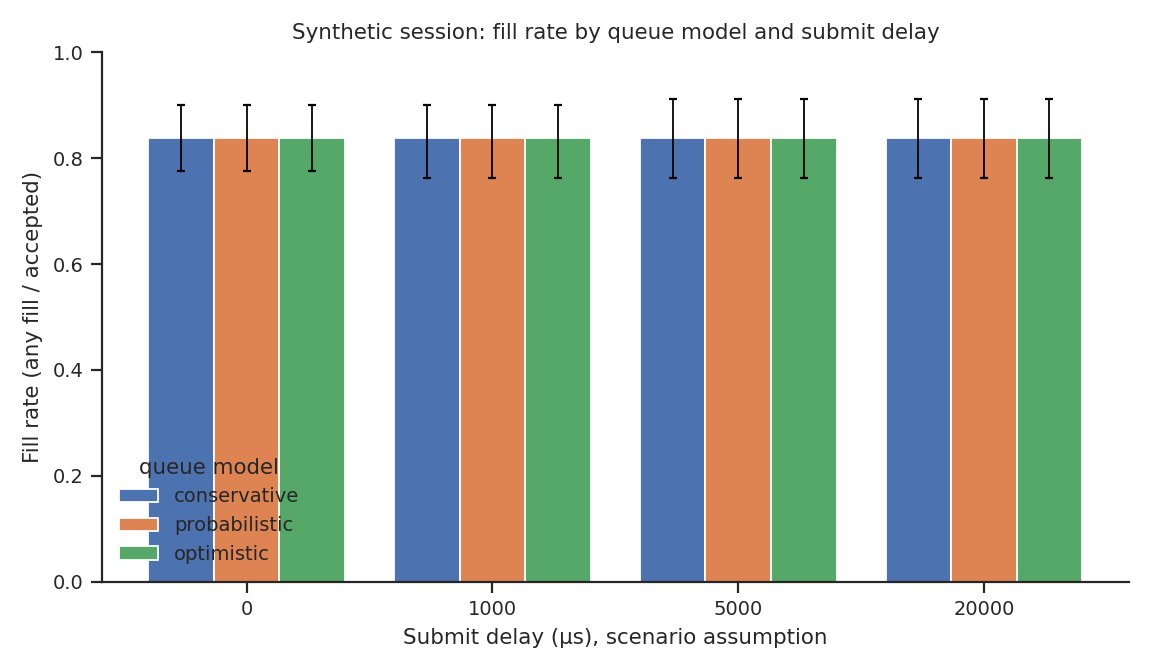

filled orders at delay 0: 201 of 240
IS percentile 50 -5.0
spread-capture percentile 50 4.0


In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "scripts" / "analysis.py").is_file():
    raise SystemExit("run this notebook from the repository root")
sys.path.insert(0, str(ROOT / "scripts"))
import analysis
from IPython.display import Image, display

def show(name):
    display(Image(filename=str(analysis.FIG / f"{name}.png")))

sens = analysis.sensitivity()
execs = analysis.executions()
print("orders", int(sens["n_orders"].iloc[0]), "cells", len(sens))
print(sens[["model", "submit_delay_us", "n_accepted", "fill_rate", "fill_rate_ci_lo", "fill_rate_ci_hi", "mean_implementation_shortfall", "mean_spread_capture"]].to_string(index=False))
analysis.plot_fill_rate(sens, analysis.FIG)
show("fill_rate_by_latency")
zero = execs[execs["submit_delay_us"] == 0]
filled = zero[zero["filled_qty"] > 0]
print("filled orders at delay 0:", len(filled), "of", len(zero))
print("IS percentile 50", analysis.descriptive_percentile(filled["implementation_shortfall"], 50))
print("spread-capture percentile 50", analysis.descriptive_percentile(filled["spread_capture"], 50))


The percentile lines are descriptive. The inferential interval in the table is the OCaml block bootstrap of the fill indicator, not of shortfall. Fills overlap in time, so the bootstrap block only partially addresses dependence.